# Forecasting

`FullForecast` splits a survey into redshift bins. In each bin it builds the data vector ($P_\ell$ in $k$-shells, $B_{\ell m}$ in triangle bins) and its covariance. From it:

```
ClassWAP ─▶ FullForecast(kmax, N_bins) ─┬─▶ pk_SNR, bk_SNR        signal-to-noise
                                        ├─▶ get_fish ─▶ FisherMat  errors, priors, best-fit shifts, corner plots
                                        └─▶ sampler  ─▶ Sampler    MCMC with Cobaya
```

The signal is set as in `Model` (see `example_pk.ipynb`). `kernels` defaults to `['N']`, and the bispectrum uses the same list minus the integrated kernels. Analytic `terms`, e.g. `'WSGR'`, go on top. The covariance is Gaussian by default, and `cov_ng=True` adds the non-Gaussian bispectrum and $P$-$B$ cross-covariance.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cosmo_wap as cw
from cosmo_wap.forecast import FullForecast
from cosmo_wap.lib import utils

plt.rcParams.update(
    {"figure.dpi": 110, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.5, "legend.frameon": False}
)

cosmo = utils.get_cosmo()
survey = cw.SurveyParams.Euclid(cosmo)
cosmo_funcs = cw.ClassWAP(cosmo, survey, compute_bias=True)

forecast = FullForecast(cosmo_funcs, kmax_func=0.15, N_bins=4)  # kmax_func can also be a function of z
print("z bins:", forecast.z_bins.round(3).tolist())
print("k_max: ", forecast.k_max_list)

z bins: [[0.9, 1.125], [1.125, 1.35], [1.35, 1.575], [1.575, 1.8]]
k_max:  [0.15 0.15 0.15 0.15]


## Signal-to-noise

`pk_SNR` and `bk_SNR` return the *squared* SNR in each redshift bin. The bins are independent, so these add up:

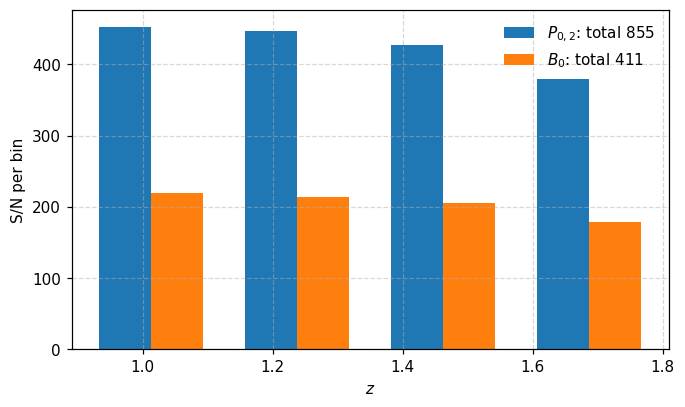

In [2]:
snr2_pk = forecast.pk_SNR(None, pkln=[0, 2], kernels=["N"], verbose=False).real
snr2_bk = forecast.bk_SNR(None, bkln=[0], bk_kernels=["N"], verbose=False).real

width = 0.08
plt.figure(figsize=(7, 4))
plt.bar(forecast.z_mid - width / 2, np.sqrt(snr2_pk), width, label=rf"$P_{{0,2}}$: total {np.sqrt(snr2_pk.sum()):.0f}")
plt.bar(forecast.z_mid + width / 2, np.sqrt(snr2_bk), width, label=rf"$B_0$: total {np.sqrt(snr2_bk.sum()):.0f}")
plt.xlabel("$z$")
plt.ylabel("S/N per bin")
plt.legend();

## Fisher matrices

`get_fish` takes the parameters, the signal and the multipoles. The parameters can be:

- cosmological: `A_s` / `ln_A_s`, `n_s`, `h`, `Omega_m`, `Omega_b`, `sigma8`, `w0`, `wa`, ...
- PNG: `fNL` (local), `fNL_eq`, `fNL_orth`. The signal must contain the matching kernel.
- bias amplitudes: `A_b_1`, `A_b_2`, `A_be`, `A_Q`, ...
- a kernel name, e.g. `LP`: the amplitude of that contribution.

Here is local PNG with a linear-bias amplitude, from the power spectrum, the bispectrum and both together:

In [3]:
params = ["fNL", "A_b_1"]
signal = dict(kernels=["N", "Loc"], verbose=False)

fish = {
    "Pk": forecast.get_fish(params, pkln=[0, 2], **signal),
    "Bk": forecast.get_fish(params, bkln=[0], **signal),
    "Pk + Bk": forecast.get_fish(params, pkln=[0, 2], bkln=[0], **signal),
}
for name, f in fish.items():
    print(f"{name:>8}: σ(fNL) = {f.get_error('fNL'):.2f}")

      Pk: σ(fNL) = 5.03
      Bk: σ(fNL) = 4.24
 Pk + Bk: σ(fNL) = 3.15


Each `FisherMat` can be added to a ChainConsumer object as a Gaussian chain, and `corner_plot` draws them (it uses LaTeX):

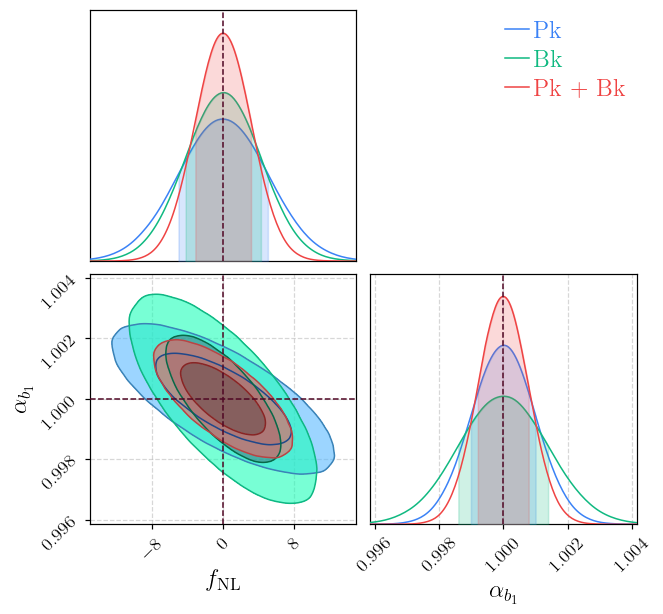

In [4]:
c = None
for name, f in fish.items():
    c = f.add_chain(c, name=name)
fig, c = fish["Pk + Bk"].corner_plot(c, figsize=(6, 6))

## Cosmology, per-bin nuisances and priors

Cosmological parameters are differentiated through CLASS. `per_bin_params` gives a nuisance an independent value in every redshift bin and marginalises it out. `add_planck_prior` adds a Planck 2018 CMB prior (`bao=True` for CMB + BAO).

σ(b_1) per bin: [0.0019 0.0021 0.0025 0.0031]


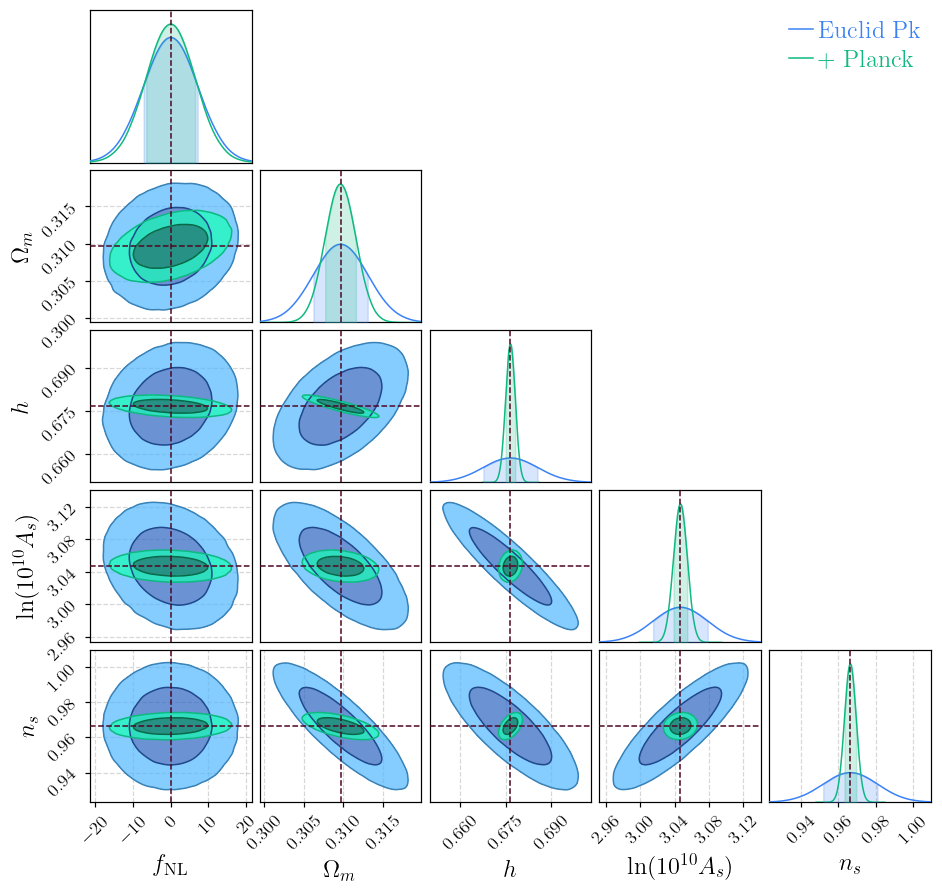

In [5]:
fish_cosmo = forecast.get_fish(
    ["fNL", "Omega_m", "h", "ln_A_s", "n_s"],
    per_bin_params=["b_1"],
    kernels=["N", "Loc"],
    pkln=[0, 2],
    verbose=False,
)
fish_planck = fish_cosmo.add_planck_prior()
print("σ(b_1) per bin:", fish_cosmo.get_per_bin_error("b_1").round(4))

c = fish_cosmo.add_chain(name="Euclid Pk")
c = fish_planck.add_chain(c, name="+ Planck")
fig, c = fish_planck.corner_plot(c, figsize=(9, 9))

`get_cumulative_fish` gives the constraint as redshift bins are added:

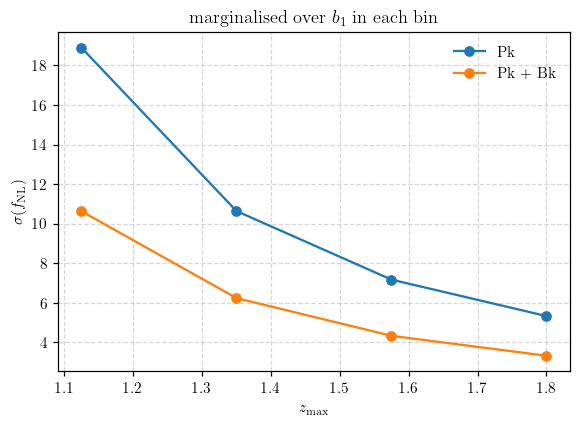

In [6]:
kwargs = dict(per_bin_params=["b_1"], kernels=["N", "Loc"], pkln=[0, 2], verbose=False)
cumulative = {
    "Pk": forecast.get_cumulative_fish(["fNL"], **kwargs),
    "Pk + Bk": forecast.get_cumulative_fish(["fNL"], bkln=[0], **kwargs),
}

plt.figure(figsize=(6, 4))
for name, fishers in cumulative.items():
    plt.plot(forecast.z_bins[:, 1], [f.get_error("fNL") for f in fishers], "o-", label=name)
plt.xlabel(r"$z_{\rm max}$")
plt.ylabel(r"$\sigma(f_{\rm NL})$")
plt.title(r"marginalised over $b_1$ in each bin")
plt.legend();

## Detecting relativistic effects

With a kernel name as a parameter, $1/\sigma(A)$ is the detection significance of that contribution. In $P(k)$ the local relativistic dipole needs two tracers, but the bispectrum of a single tracer already has one (see `example_bk.ipynb`):

In [7]:
bright, faint = survey.BF_split(3e-16)
forecast_mt = FullForecast(cw.ClassWAP(cosmo, [bright, faint], compute_bias=True), kmax_func=0.15, N_bins=4)

gr = dict(kernels=["N", "LP"], verbose=False)
fish_gr = {
    "Pk, bright x faint": forecast_mt.get_fish(["LP"], pkln=[0, 1, 2], all_tracer=True, **gr),  # XX, XY and YY
    "Bk, single tracer": forecast.get_fish(["LP"], bkln=[0, 1, 2], **gr),
}
for name, f in fish_gr.items():
    print(f"{name}: S/N = {1 / f.get_error('LP'):.2f}")

Pk, bright x faint: S/N = 1.48
Bk, single tracer: S/N = 1.35


## Best-fit shifts from neglected effects

`bias_list` gives the shift in every parameter when the model leaves a contribution out but the data contain it. Here the fit neglects the integrated effects (lensing magnification, time delay, ISW) while fitting $f_{\rm NL}$:

Δ fNL = 14.5, or 2.9σ


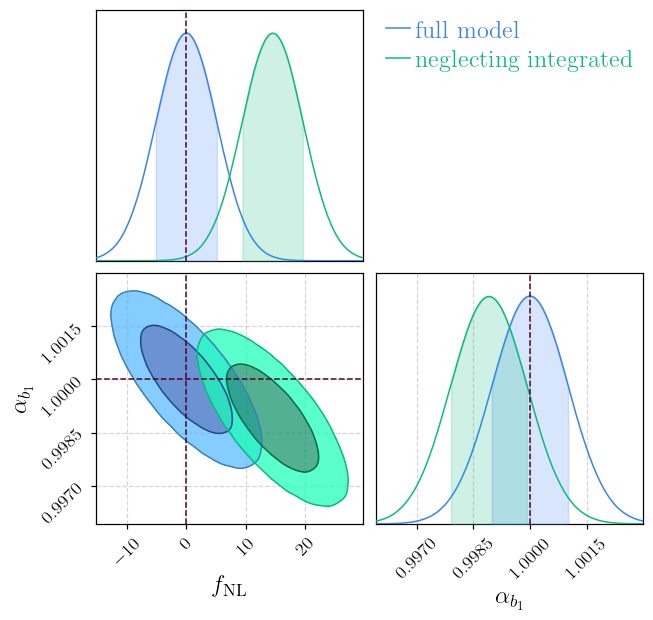

In [8]:
fish_bfb = forecast.get_fish(["fNL", "A_b_1"], kernels=["N", "LP", "Loc"], pkln=[0, 2], bias_list="GRI", verbose=False)
shift = fish_bfb.bias[-1]["fNL"]
print(f"Δ fNL = {shift:.1f}, or {shift / fish_bfb.get_error('fNL'):.1f}σ")

c = fish_bfb.add_chain(bias_values={}, name="full model")
c = fish_bfb.add_chain(c, name="neglecting integrated")  # centred on the fiducial + shift
fig, c = fish_bfb.corner_plot(c, figsize=(6, 6))

## MCMC

`forecast.sampler` takes the same arguments as `get_fish`. It builds a Cobaya sampler on a mock data vector from the fiducial model, with the same covariance, and uses the Fisher matrix as its proposal. A run takes minutes with $P(k)$ and longer with the bispectrum. For production runs under MPI see `mpi_mcmc.py`.

In [ ]:
sampler = forecast.sampler(["fNL", "A_b_1"], kernels=["N", "Loc"], pkln=[0, 2], bkln=[0])
sampler.run()  # until Gelman-Rubin R - 1 < R_stop (default 0.005)

c = sampler.add_chain(name="MCMC")
c = fish["Pk + Bk"].add_chain(c, name="Fisher")
fig, c = sampler.corner_plot(c, figsize=(6, 6))

`sampler.save(path)` stores the chain, and `Sampler.load(path, forecast)` reloads it.

## Next

The [forecast docs](https://cosmowap.readthedocs.io/en/latest/forecast.html) cover the rest: non-Gaussian covariances, `all_m` and the bispectrum leg placements, super-sample covariance (`'delta_b'`), luminosity-function priors and grids of Fisher matrices over survey splits (`get_fish_list`).